# Ambient Machine Learning Model

## Setting up the notebook

In [130]:
%matplotlib notebook

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import librosa

from librosa import display
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

## SciKit-learn modules
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge
from sklearn.neighbors import KNeighborsRegressor, RadiusNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import r2_score

### Step 1: Data Preparation

In [132]:
## Load Sensor 1
sens01 = pd.read_csv('./Data/sensor01-simplified.csv', sep=',', index_col='Date')
num_points, num_attributes = sens01.shape
print("There are {} data points, each with {} attributes.". format(num_points, num_attributes))
sens01.head()

There are 92 data points, each with 5 attributes.


,Time,Average Temp,Average RH,Average CO2,Average Lux
Date,,,,,
28-Apr,12 PM,28.75,50.18,365.71,1078.93
28-Apr,1 PM,25.61,58.43,331.74,2108.95
28-Apr,2 PM,25.47,58.66,307.79,2738.20
28-Apr,3 PM,25.61,59.85,325.75,2743.88
28-Apr,4 PM,26.08,59.67,336.04,2738.50


In [133]:
## Load Sensor 2
sens02 = pd.read_csv('./Data/sensor02-simplified.csv', sep=',', index_col='Date')
num_points, num_attributes = sens02.shape
print("There are {} data points, each with {} attributes.". format(num_points, num_attributes))
sens02.head()

There are 92 data points, each with 5 attributes.


,Time,Average Temp,Average RH,Average CO2,Average Lux
Date,,,,,
28-Apr,12 PM,28.26,55.54,767.00,891.67
28-Apr,1 PM,28.09,54.77,759.00,1128.00
28-Apr,2 PM,26.86,58.04,756.60,2348.00
28-Apr,3 PM,27.19,57.19,746.00,2348.23
28-Apr,4 PM,27.35,58.52,747.27,2267.05


In [134]:
## Load Optimal
optimal = pd.read_csv('./Data/opt.csv', sep=',', index_col='Date')
num_points, num_attributes = optimal.shape
print("There are {} data points, each with {} attributes.". format(num_points, num_attributes))
optimal.head()

There are 92 data points, each with 5 attributes.


,Time,Average Temp,Average RH,Average CO2,Average Lux
Date,,,,,
28-Apr,12:00 PM,25,60,1200,5000.0
28-Apr,1:00 PM,25,60,1200,5000.0
28-Apr,2:00 PM,25,60,1200,5000.0
28-Apr,3:00 PM,25,60,1200,5000.0
28-Apr,4:00 PM,25,60,1200,5000.0


### Step 2: Graphs

<IPython.core.display.Javascript object>


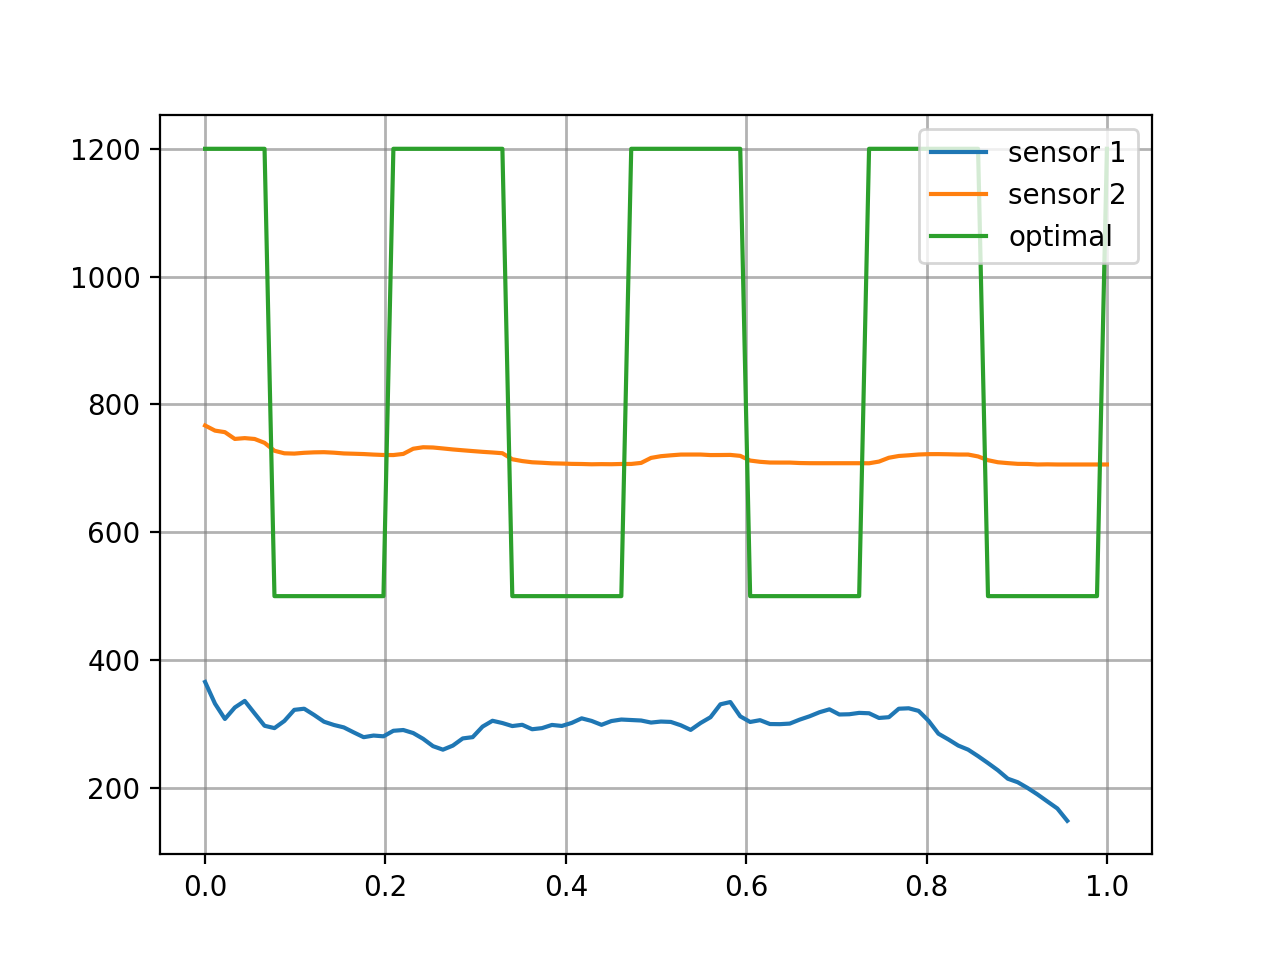

In [135]:
## Light Intensity (Lux) Graph

fig = plt.figure()
ax = plt.axes()
x = np.linspace(0, 1, 92)
sensor01, = plt.plot(x, sens01['Average CO2'], label='sensor 1')
sensor02, = plt.plot(x, sens02['Average CO2'], label='sensor 2')
optimal, = plt.plot(x, optimal['Average CO2'], label='optimal')
#plt.legend(handles=[sensor01, sensor02], loc='lower right')
plt.legend()
plt.grid(b=True, which='major', color='gray', alpha=0.6, lw=1)
plt.show()
plt.savefig("CO2.png") # save as png